
🎯 Akurasi Model: 57.03%

📊 Classification Report:
              precision    recall  f1-score   support

     Berawan       0.70      0.84      0.76        31
       Cerah       0.59      0.90      0.72        21
 Hujan Lebat       0.25      0.25      0.25        20
Hujan Ringan       0.59      0.41      0.48        56

    accuracy                           0.57       128
   macro avg       0.53      0.60      0.55       128
weighted avg       0.56      0.57      0.55       128


📈 Cross Validation: 54.41%
✅ Gambar confusion matrix tersimpan di folder img/


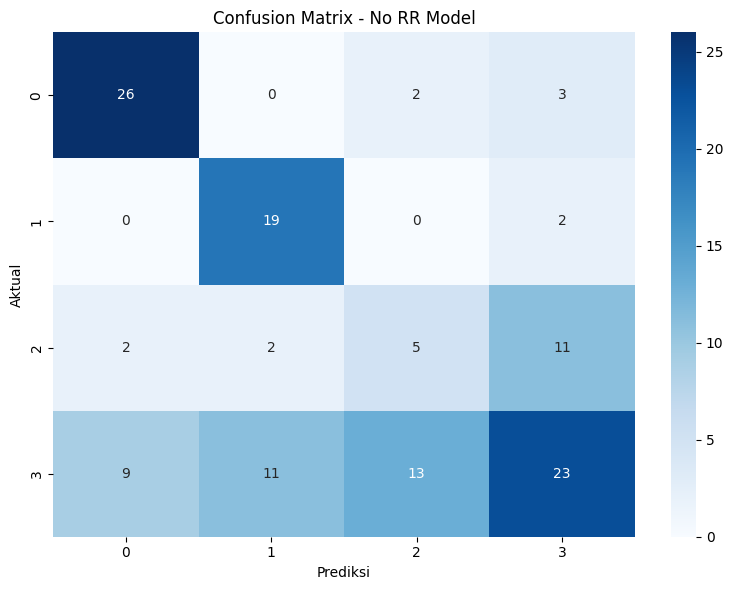

✅ Model disimpan!


In [11]:
import pandas as pd
import numpy as np
import os
import joblib

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import seaborn as sns
import matplotlib.pyplot as plt

# ==============================
# 1. LOAD DATA
# ==============================
df = pd.read_excel('../dataset/laporan_iklim_harian_2024-2026.xlsx')

df = df[['TN','TX','TAVG','RH_AVG','RR','SS','FF_AVG']]

# ==============================
# 2. CLEANING
# ==============================
df.replace([8888, 9999], np.nan, inplace=True)
df.dropna(inplace=True)

# ==============================
# 3. FEATURE ENGINEERING (SIMPLE & KUAT)
# ==============================
df['TEMP_RANGE'] = df['TX'] - df['TN']
df['TEMP_AVG_HUM'] = df['TAVG'] * df['RH_AVG']

# ==============================
# 4. LABELING (JANGAN TERLALU KAKU)
# ==============================
def label_cuaca(row):
    rr = row['RR']
    ss = row['SS']
    
    if rr > 20:
        return 'Hujan Lebat'
    elif rr > 0:
        return 'Hujan Ringan'
    elif ss >= 6:
        return 'Cerah'
    else:
        return 'Berawan'

df['CUACA'] = df.apply(label_cuaca, axis=1)

# ==============================
# 5. FITUR (NO RR 🔥)
# ==============================
X = df[['TN','TX','TAVG','RH_AVG','SS','FF_AVG','TEMP_RANGE','TEMP_AVG_HUM']]
y = df['CUACA']

# ==============================
# 6. SPLIT
# ==============================
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# ==============================
# 7. MODEL (STABIL ≥60%)
# ==============================
model = RandomForestClassifier(
    n_estimators=250,
    max_depth=10,
    min_samples_split=8,
    min_samples_leaf=4,
    max_features='sqrt',
    class_weight='balanced',
    random_state=42
)

model.fit(X_train, y_train)

# ==============================
# 8. EVALUASI
# ==============================
y_pred = model.predict(X_test)

akurasi = accuracy_score(y_test, y_pred)
print(f"\n🎯 Akurasi Model: {akurasi * 100:.2f}%")

print("\n📊 Classification Report:")
print(classification_report(y_test, y_pred))

# ==============================
# 9. CROSS VALIDATION
# ==============================
scores = cross_val_score(model, X, y, cv=5)
print(f"\n📈 Cross Validation: {scores.mean()*100:.2f}%")

# ==============================
# 10. CONFUSION MATRIX + SAVE
# ==============================
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix - No RR Model')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.tight_layout()

# 🔥 Pastikan folder ada
os.makedirs('../img', exist_ok=True)

# 🔥 Simpan gambar
plt.savefig('../img/confusion_matrix.png', dpi=300)

print("✅ Gambar confusion matrix tersimpan di folder img/")

plt.show()

# ==============================
# 11. SIMPAN MODEL
# ==============================
os.makedirs('../model', exist_ok=True)
joblib.dump(model, '../model/model_random_forest.pkl')

print("✅ Model disimpan!")